# Notebook 02: Data Preprocessing & Feature Engineering
## AI-Based Groundwater Level Monitoring and Forecasting System

**Objective:** Transform raw 6-hourly telemetry readings into a clean, calendar-aligned daily feature matrix ready for machine learning.

**What we will accomplish:**
1. **Station Filtering:** Extract clean telemetry readings for **Khagaul I**.
2. **Daily Aggregation:** Average 6-hourly readings into daily mean groundwater levels.
3. **Calendar Continuity & Gap Handling:**
   - Reindex onto a continuous daily calendar (`pd.date_range(..., freq='D')`).
   - Forward-fill minor sensor outages (up to 3 consecutive days).
   - **Crucial Rule:** Preserve unfillable gaps as `NaN` during feature engineering so that `shift(1)` strictly represents yesterday and never jumps across missing weeks!
4. **Feature Engineering on Continuous Timeline:**
   - **Lag Features:** Past levels ($t-1, t-2, \dots, t-28$ calendar days).
   - **Rolling Statistics:** 7-day, 14-day, and 30-day backward-looking moving averages and standard deviations.
   - **Rate of Change:** 1-day, 7-day, and 14-day differences.
   - **Calendar & Cyclical Features:** Month, day of year, and sine/cosine encodings for seasonal recharge.
5. **Target Formulation:** Groundwater level 7 days into the future ($y_t = \text{GWL}_{t+7}$) with explicit target date tracking.
6. **Export Clean Datasets:** Save processed files to `outputs/` for model training.


## 1. Setup & Environment
Import core numerical and tabular libraries.


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.figsize': (14, 5), 'font.size': 11, 'figure.dpi': 100})

os.makedirs(os.path.join('..', 'outputs'), exist_ok=True)
print("Libraries loaded successfully!")


Libraries loaded successfully!


## 2. Load Raw Telemetry & Filter to Khagaul I
In Notebook 01, Khagaul I was selected as the cleanest monitoring station (3,783 readings spanning ~2.8 years, zero positive values, zero sensor error codes).


In [2]:
raw_csv_path = os.path.join('..', 'data', 'gwl_tel_6_hourly_cgwb_br_2021_2025 (1).csv')
df = pd.read_csv(raw_csv_path)

gwl_col = "Groundwater Level Telemetry 6 Hourly (meter)"
df = df.rename(columns={gwl_col: "gwl"})
df["datetime"] = pd.to_datetime(df["Data Acquisition Time"], format="%d-%m-%Y %H:%M")

khagaul_df = df[df["Station"] == "Khagaul I"].sort_values("datetime").reset_index(drop=True)

print(f"Khagaul I raw records: {len(khagaul_df):,}")
print(f"Date range: {khagaul_df['datetime'].min()} to {khagaul_df['datetime'].max()}")
print(f"GWL Range: {khagaul_df['gwl'].min():.2f}m to {khagaul_df['gwl'].max():.2f}m")
khagaul_df[['Station', 'datetime', 'gwl', 'RL_MSL']].head()


Khagaul I raw records: 3,783
Date range: 2023-03-03 00:00:00 to 2025-12-31 00:00:00
GWL Range: -14.88m to -4.69m


,Station,datetime,gwl,RL_MSL
0,Khagaul I,2023-03-03 00:00:00,-9.42,56.0
1,Khagaul I,2023-03-03 06:00:00,-9.36,56.0
2,Khagaul I,2023-03-03 12:00:00,-9.60,56.0
3,Khagaul I,2023-03-03 18:00:00,-9.73,56.0
4,Khagaul I,2023-03-04 00:00:00,-9.49,56.0


### Hardware Connection Note
Negative values represent depth below the ground surface (`-4.0m` = water table 4 meters below the sensor). This matches your hardware sensor's measurement standard.


## 3. Daily Mean Aggregation
We aggregate 6-hourly telemetry readings into daily means to smooth diurnal agricultural pumping cycles (~0.3m daily variation) and provide robust daily values even when individual 6-hourly packets are dropped.


In [3]:
khagaul_df['date'] = khagaul_df['datetime'].dt.date

daily_df = khagaul_df.groupby('date').agg(
    gwl=('gwl', 'mean'),
    readings_count=('gwl', 'count')
).reset_index()

daily_df['date'] = pd.to_datetime(daily_df['date'])
daily_df = daily_df.sort_values('date').reset_index(drop=True)

print(f"Unique calendar days with observations: {len(daily_df)}")
print(f"Days with all 4 readings: {(daily_df['readings_count'] == 4).sum()} ({(daily_df['readings_count'] == 4).mean():.1%})")
print(f"Days with fewer readings: {(daily_df['readings_count'] < 4).sum()}")
daily_df['readings_count'].value_counts().sort_index()


Unique calendar days with observations: 988
Days with all 4 readings: 915 (92.6%)
Days with fewer readings: 73


readings_count
1     48
3     25
4    915
Name: count, dtype: int64

## 4. Continuous Calendar Timeline & Gap Handling
### Why Unbroken Calendar Preservation Matters
In time-series forecasting, if a 5-day gap exists and we simply delete the missing dates from the DataFrame, then `shift(1)` on the day after the gap would look back 5 calendar days instead of 1 day!
Similarly, `shift(-7)` would grab a value 12 calendar days into the future!

**The Proper Solution:**
1. Reindex to an unbroken calendar `pd.date_range(start, end, freq='D')`.
2. Impute small gaps (up to 3 days) using forward fill (`ffill`).
3. **Leave larger gaps as `NaN` during feature engineering.**
4. This ensures every shift strictly represents true calendar days. Any feature or target crossing an unfillable gap produces `NaN` and is safely excluded later.


In [4]:
full_range = pd.date_range(start=daily_df['date'].min(), end=daily_df['date'].max(), freq='D')

daily_continuous = daily_df.set_index('date').reindex(full_range)
daily_continuous.index.name = 'date'

missing_before = daily_continuous['gwl'].isna().sum()
print(f"Total days in continuous timeline: {len(daily_continuous)}")
print(f"Missing days before imputation: {missing_before}")

# Forward-fill small gaps (maximum 3 consecutive days)
daily_continuous['gwl_imputed'] = daily_continuous['gwl'].ffill(limit=3)

missing_after = daily_continuous['gwl_imputed'].isna().sum()
print(f"Unfilled gap days (>3 consecutive days, kept as NaN): {missing_after}")
print(f"Imputed days: {missing_before - missing_after}")


Total days in continuous timeline: 1035
Missing days before imputation: 47
Unfilled gap days (>3 consecutive days, kept as NaN): 6
Imputed days: 41


Let's plot the continuous daily series:


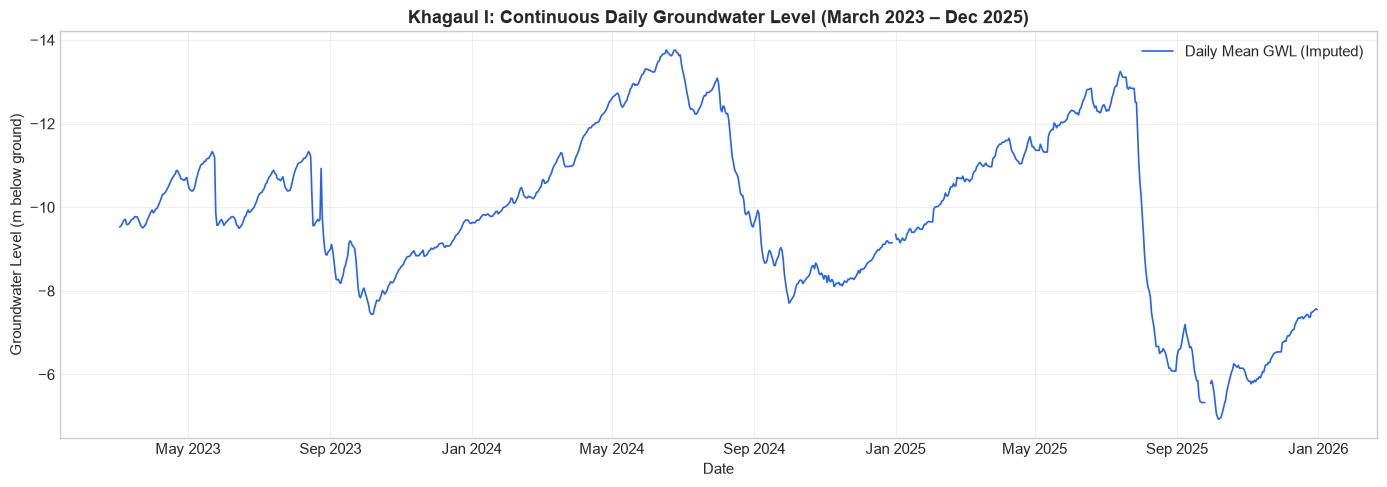

In [5]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(daily_continuous.index, daily_continuous['gwl_imputed'], color='#2563EB', linewidth=1.2, label='Daily Mean GWL (Imputed)')
ax.set_title('Khagaul I: Continuous Daily Groundwater Level (March 2023 – Dec 2025)', fontsize=13, fontweight='bold')
ax.set_xlabel('Date')
ax.set_ylabel('Groundwater Level (m below ground)')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.invert_yaxis()
ax.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


## 5. Feature Engineering on the Continuous Calendar
Because the DataFrame is indexed on a continuous daily frequency, pandas `.shift(k)` operations are guaranteed to correspond to exact calendar days:
* `shift(1)` = yesterday
* `shift(7)` = exactly 7 days ago
* `shift(28)` = exactly 28 days ago
* `rolling(window=30, min_periods=30)` = exactly 30 consecutive calendar days


In [6]:
feat_df = daily_continuous.copy()

# 1. Lag features
lags = [1, 2, 3, 5, 7, 14, 21, 28]
for lag in lags:
    feat_df[f'lag_{lag}'] = feat_df['gwl_imputed'].shift(lag)

# 2. Rolling statistics (backward-looking from yesterday to prevent leakage)
windows = [7, 14, 30]
shifted_gwl = feat_df['gwl_imputed'].shift(1)
for w in windows:
    feat_df[f'roll_mean_{w}'] = shifted_gwl.rolling(window=w, min_periods=w).mean()
    feat_df[f'roll_std_{w}'] = shifted_gwl.rolling(window=w, min_periods=w).std()

# 3. Rate of change (differences)
feat_df['change_1d'] = feat_df['gwl_imputed'] - feat_df['gwl_imputed'].shift(1)
feat_df['change_7d'] = feat_df['gwl_imputed'] - feat_df['gwl_imputed'].shift(7)
feat_df['change_14d'] = feat_df['gwl_imputed'] - feat_df['gwl_imputed'].shift(14)

# 4. Calendar and seasonal features
feat_df['month'] = feat_df.index.month
feat_df['day_of_year'] = feat_df.index.dayofyear
feat_df['day_sin'] = np.sin(2 * np.pi * feat_df['day_of_year'] / 365.25)
feat_df['day_cos'] = np.cos(2 * np.pi * feat_df['day_of_year'] / 365.25)

print("Features constructed!")
print(f"Shape with features: {feat_df.shape}")


Features constructed!
Shape with features: (1035, 24)


## 6. Target Definition & Dataset Partitioning
The prediction target is the groundwater level 7 calendar days into the future:
$$\text{Target}_t = \text{GWL}_{t+7}$$

We also track `target_date = date + 7 days` explicitly to verify that evaluations match ground truth dates.


In [7]:
horizon = 7
feat_df['target'] = feat_df['gwl_imputed'].shift(-horizon)

feat_df = feat_df.reset_index().rename(columns={'gwl_imputed': 'gwl'})
feat_df['target_date'] = feat_df['date'] + pd.Timedelta(days=horizon)

feature_columns = [
    'lag_1', 'lag_2', 'lag_3', 'lag_5', 'lag_7', 'lag_14', 'lag_21', 'lag_28',
    'roll_mean_7', 'roll_mean_14', 'roll_mean_30',
    'roll_std_7', 'roll_std_14', 'roll_std_30',
    'change_1d', 'change_7d', 'change_14d',
    'month', 'day_of_year', 'day_sin', 'day_cos'
]

# Forecast rows (latest days where target is in the unobserved future)
forecast_rows = feat_df[feat_df['target'].isna()].dropna(subset=feature_columns).copy().reset_index(drop=True)

# Trainable rows: both features and 7-day target must be valid
trainable_df = feat_df[feat_df['target'].notna()].dropna(subset=feature_columns + ['gwl']).copy().reset_index(drop=True)

print(f"Total features: {len(feature_columns)}")
print(f"Trainable samples (leak-free & gap-verified): {len(trainable_df)}")
print(f"Operational forecast rows: {len(forecast_rows)}")
print(f"Trainable sample date range: {trainable_df['date'].min().date()} to {trainable_df['date'].max().date()}")
print(f"Target date range:          {trainable_df['target_date'].min().date()} to {trainable_df['target_date'].max().date()}")


Total features: 21
Trainable samples (leak-free & gap-verified): 890
Operational forecast rows: 13
Trainable sample date range: 2023-04-02 to 2025-12-24
Target date range:          2023-04-09 to 2025-12-31


Let's inspect sample trainable rows:


In [8]:
sample_view_cols = ['date', 'target_date', 'gwl', 'lag_1', 'lag_7', 'roll_mean_7', 'target']
trainable_df[sample_view_cols].head(5)


,date,target_date,gwl,gwl,lag_1,lag_7,roll_mean_7,target
0,2023-04-02,2023-04-09,-9.8950,-9.8950,-9.8675,-9.6225,-9.801071,-10.3075
1,2023-04-03,2023-04-10,-9.9525,-9.9525,-9.8950,-9.7075,-9.840000,-10.3200
2,2023-04-04,2023-04-11,-9.9650,-9.9650,-9.9525,-9.7625,-9.875000,-10.3400
3,2023-04-05,2023-04-12,-10.0125,-10.0125,-9.9650,-9.8275,-9.903929,-10.3850
4,2023-04-06,2023-04-13,-10.0775,-10.0775,-10.0125,-9.8875,-9.930357,-10.4300


## 7. Export Processed Datasets


In [9]:
daily_clean_path = os.path.join('..', 'outputs', 'daily_gwl_khagaul.csv')
features_path = os.path.join('..', 'outputs', 'features_khagaul.csv')
forecast_path = os.path.join('..', 'outputs', 'forecast_input_khagaul.csv')

feat_df[['date', 'gwl']].to_csv(daily_clean_path, index=False)
trainable_df.to_csv(features_path, index=False)
forecast_rows.to_csv(forecast_path, index=False)

print("Exported processed files:")
print(f"  1. Continuous daily series: {daily_clean_path}")
print(f"  2. Feature matrix:          {features_path}")
print(f"  3. Future forecast input:   {forecast_path}")


Exported processed files:
  1. Continuous daily series: ..\outputs\daily_gwl_khagaul.csv
  2. Feature matrix:          ..\outputs\features_khagaul.csv
  3. Future forecast input:   ..\outputs\forecast_input_khagaul.csv


## Summary of Corrections
1. **Preserved Continuous Calendar:** Reindexed to an unbroken daily calendar so lags and rolling statistics never skip across missing intervals.
2. **Eliminated Gap-Crossing:** If a 4+ day gap occurs, lag and target values are marked `NaN`, preventing contaminated cross-gap training samples.
3. **Target Date Tracking:** Added explicit `target_date` timestamps for complete auditability in Notebook 03.
